In [6]:
import sys
from pathlib import Path
import io
import asyncio
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Resolver ruta hacia 'src' para importar módulos del proyecto
CURRENT_DIR = Path.cwd().resolve()
SRC_PATH = str(CURRENT_DIR.parent) if CURRENT_DIR.name == "notebooks" else str(CURRENT_DIR / "src")
if SRC_PATH not in sys.path:
    sys.path.insert(0, SRC_PATH)

from config.settings import settings
from dependencies.dependencies import get_storage_repository

# 2. Conectar a Cloudflare R2 vía Storage Repository y descargar en memoria
storage = get_storage_repository()
R2_KEY = "raw/yfinance/stocks_2010_2023.parquet"
print(f"Descargando dataset bursátil desde s3://{settings.s3_bucket_name}/{R2_KEY}...")
data = asyncio.run(storage.get(R2_KEY))
df = pd.read_parquet(io.BytesIO(data))


print("=== 1. RESUMEN ESTRUCTURAL DEL ARCHIVO ===")
print(f"Dimensiones         : {df.shape[0]} filas x {df.shape[1]} columnas")
print(f"Fecha inicial       : {df.index.min().strftime('%Y-%m-%d')}")
print(f"Fecha final         : {df.index.max().strftime('%Y-%m-%d')}")
print(f"Fechas duplicadas   : {df.index.duplicated().sum()}")
print(f"Orden cronológico   : {df.index.is_monotonic_increasing}")
print(f"Total nulos (NaN)   : {df.isna().sum().sum()}")
print("\nTipos de datos por bloque:")
print(df.dtypes.value_counts())

print("\n=== 2. SESIONES BURSÁTILES POR AÑO ===")
sesiones_anio = df.groupby(df.index.year).size()


Descargando dataset bursátil desde s3://tfm-master-prediccion-bancos-usa/raw/yfinance/stocks_2010_2023.parquet...
=== 1. RESUMEN ESTRUCTURAL DEL ARCHIVO ===
Dimensiones         : 3522 filas x 36 columnas
Fecha inicial       : 2010-01-04
Fecha final         : 2023-12-29
Fechas duplicadas   : 0
Orden cronológico   : True
Total nulos (NaN)   : 0

Tipos de datos por bloque:
float64    30
int64       6
Name: count, dtype: int64

=== 2. SESIONES BURSÁTILES POR AÑO ===
Date      2010  2011  2012  2013  2014  2015  2016  2017  2018  2019  2020  \
Sesiones   252   252   250   252   252   252   252   251   251   252   253   

Date      2021  2022  2023  
Sesiones   252   251   250  


# Verificación de Nulos, Regla High >= Low y Rangos por Banco
Se certifica banco por banco si hay nulos, si se cumple que el máximo diario supera al mínimo, y en qué rango de precios y volumen se mueve cada entidad.

In [7]:
tickers = ["JPM", "BAC", "WFC", "GS", "MS", "C"]
resumen_calidad = []

for t in tickers:
    cols_banco = [f"{metric}_{t}" for metric in ["Open", "High", "Low", "Close", "Adj Close", "Volume"]]
    
    high = df[f"High_{t}"]
    low = df[f"Low_{t}"]
    open_p = df[f"Open_{t}"]
    close = df[f"Close_{t}"]
    adj_close = df[f"Adj Close_{t}"]
    vol = df[f"Volume_{t}"]
    
    resumen_calidad.append({
        "Banco": t,
        "Nulos Totales": df[cols_banco].isna().sum().sum(),
        "Fallos High < Low": (high < low).sum(),
        "Fallos High == Low": (high == low).sum(),
        "Fallos Open/Close fuera de [Low, High]": ((high < np.maximum(open_p, close) - 1e-4) | (low > np.minimum(open_p, close) + 1e-4)).sum(),
        "Volumen <= 0": (vol <= 0).sum(),
        "Close Mín ($)": close.min(),
        "Close Máx ($)": close.max(),
        "Adj Close Mín ($)": adj_close.min(),
        "Adj Close Máx ($)": adj_close.max()
    })

df_calidad = pd.DataFrame(resumen_calidad).set_index("Banco")
print("=== 3. AUDITORÍA DE NULOS, COHERENCIA HIGH/LOW Y RANGOS ===")
display(df_calidad.round(2))


=== 3. AUDITORÍA DE NULOS, COHERENCIA HIGH/LOW Y RANGOS ===


,Nulos Totales,Fallos High < Low,Fallos High == Low,"Fallos Open/Close fuera de [Low, High]",Volumen <= 0,Close Mín ($),Close Máx ($),Adj Close Mín ($),Adj Close Máx ($)
Banco,,,,,,,,,
JPM,0,0,0,0,0,28.38,171.78,19.03,159.80
BAC,0,0,0,0,0,4.99,49.38,3.84,43.90
WFC,0,0,0,0,0,21.14,65.93,15.14,52.73
GS,0,0,0,0,0,87.70,423.85,66.51,375.48
MS,0,0,0,0,0,12.36,108.73,8.79,94.02
C,0,0,0,0,0,23.11,81.91,16.90,66.83


Tabla y Gráfico de la Media Anual por Banco (2010–2023)
Calcula el precio medio por año de cada banco y genera una cuadrícula de 6 gráficos (2x3) comparando la media anual del precio nominal (Close) frente al ajustado (Adj Close).

=== 4. TABLA DE PRECIO MEDIO ANUAL (ADJ CLOSE en USD) ===


,JPM,BAC,WFC,GS,MS,C
Año,,,,,,
2010,26.43,11.23,18.35,115.95,18.92,29.30
2011,26.07,7.69,18.46,98.60,15.32,27.31
2012,26.77,6.51,22.18,84.78,11.81,23.56
2013,36.45,10.41,27.89,121.72,18.50,35.37
2014,41.98,12.70,35.92,136.56,23.73,36.82
2015,47.31,13.02,40.13,153.90,26.39,39.14
2016,50.06,12.29,36.94,136.96,22.44,34.28
2017,71.93,19.99,42.74,191.63,35.40,49.16
2018,88.44,24.39,44.15,193.60,39.10,52.87


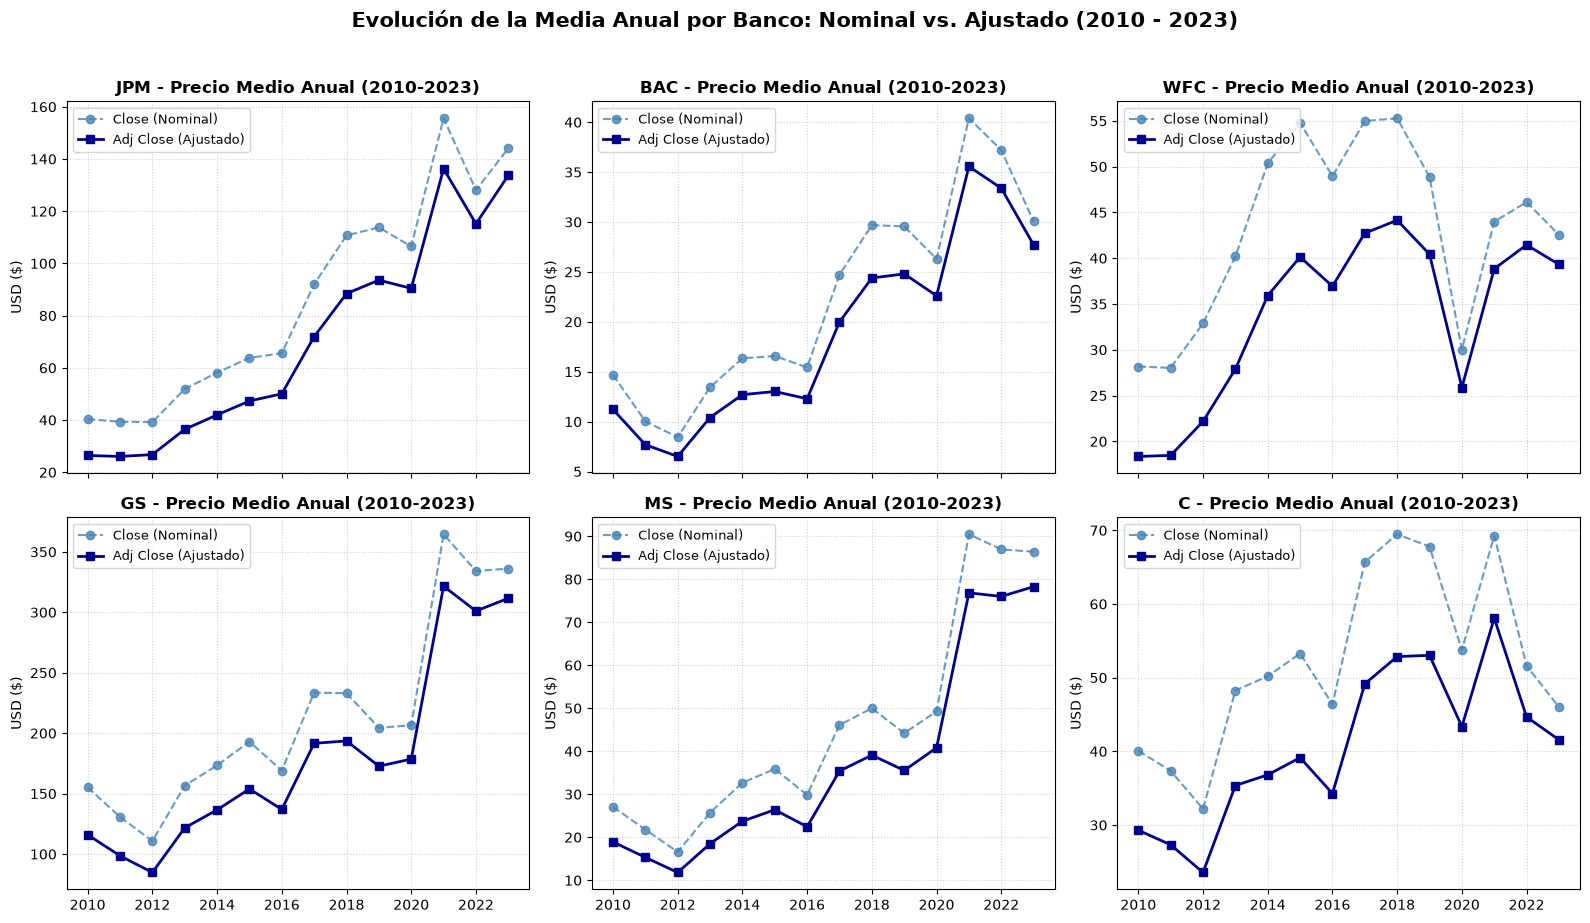

In [8]:
# 1. Calcular medias anuales de Close y Adj Close
cols_close = [f"Close_{t}" for t in tickers]
cols_adj = [f"Adj Close_{t}" for t in tickers]

medias_close = df[cols_close].groupby(df.index.year).mean()
medias_adj = df[cols_adj].groupby(df.index.year).mean()

print("=== 4. TABLA DE PRECIO MEDIO ANUAL (ADJ CLOSE en USD) ===")
medias_adj_clean = medias_adj.copy()
medias_adj_clean.columns = tickers
medias_adj_clean.index.name = "Año"
display(medias_adj_clean.round(2))

# 2. Graficar la evolución de la media anual por banco (Subplots 2x3)
fig, axes = plt.subplots(2, 3, figsize=(16, 9), sharex=True)
axes = axes.flatten()

anios = medias_close.index

for i, t in enumerate(tickers):
    ax = axes[i]
    ax.plot(anios, medias_close[f"Close_{t}"], marker="o", linestyle="--", color="steelblue", label="Close (Nominal)", alpha=0.8)
    ax.plot(anios, medias_adj[f"Adj Close_{t}"], marker="s", linewidth=2, color="darkblue", label="Adj Close (Ajustado)")
    
    ax.set_title(f"{t} - Precio Medio Anual (2010-2023)", fontsize=12, fontweight="bold")
    ax.set_ylabel("USD ($)")
    ax.set_xticks(anios[::2])  # Mostrar años de 2 en 2 para que no se solapen
    ax.grid(True, linestyle=":", alpha=0.6)
    ax.legend(loc="upper left", fontsize=9)

plt.suptitle("Evolución de la Media Anual por Banco: Nominal vs. Ajustado (2010 - 2023)", fontsize=15, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()